In [23]:
# import needed libraries

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt
import numpy as np

In [26]:
# initialize the neural network model
model = Sequential([
    Dense(10, activation='relu', input_shape=(1,)),  # Hidden layer 1
    Dense(10, activation='relu'),                     # Hidden layer 2
    Dense(1)
])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


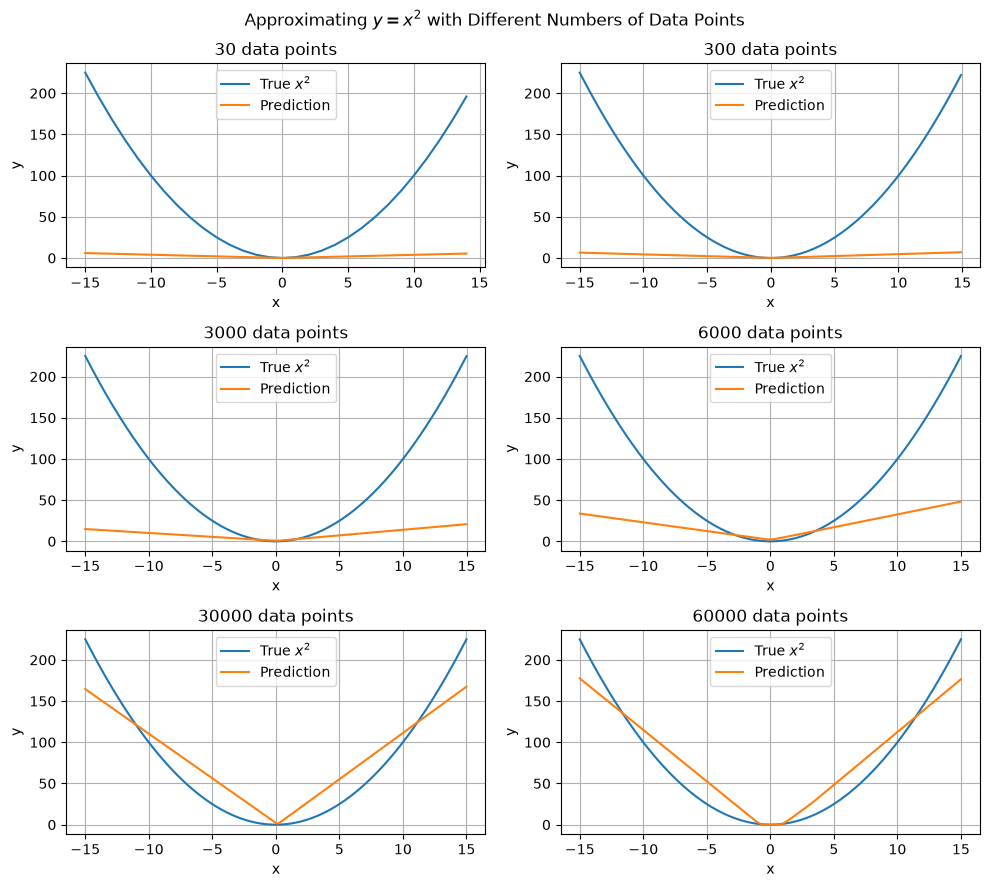

In [28]:
# Compile the model and save initial weights
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(),
    loss='mse'
)

initial_weights = model.get_weights()

# Define step sizes and create plots
step_sizes = [1, 0.1, 0.01, 0.005, 0.001, 0.0005]
plt.rcParams['axes.grid'] = True

fig, axes = plt.subplots(3, 2, figsize=(10, 9))
fig.subplots_adjust(hspace=0.4, top=0.85)
fig.suptitle('Approximating $y=x^2$ with Different Numbers of Data Points')

# Train and plot for each dataset size
for i, step_size in enumerate(step_sizes):
    x = np.arange(-15, 15, step_size).reshape(-1, 1)
    y = x**2

    model.fit(x, y, verbose=0)
    y_pred = model.predict(x, verbose=1)

    # Reset weights so each experiment starts from scratch
    model.set_weights(initial_weights)

    axes[i//2, i%2].plot(x, y, label='True $x^2$')
    axes[i//2, i%2].plot(x, y_pred, label='Prediction')

    axes[i//2, i%2].set_title(f'{len(x)} data points')
    axes[i//2, i%2].set_xlabel('x')
    axes[i//2, i%2].set_ylabel('y')
    axes[i//2, i%2].legend()

plt.tight_layout()
plt.show()

In [6]:
# ways of setting activation layer

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, ReLU, Activation

# activation inside the Dense layer: two operations in one layer
model = Sequential()
model.add(Dense(784, activation='relu', input_shape=(784,)))
# model.add(Activation='relu') 

# Using a separate Activation layer: add the activation as its own layer
model.add(Dense(784))
model.add(ReLU(threshold=0.0)) 

In [ ]:
# without parameters
model = Sequential()
model.add(layers.Dense(784, activation='relu'))

from tensorflow.keras import activations

# with parameters
model.add(Dense(784, activation=lambda x:activations.relu(x, threshold=0.1)))